# CIFAR-10 Classification — Fast Transfer Learning
**ICE 4112 | AI Lab | BAUET**  
**Dataset:** CIFAR-10 | **Pretrained model:** MobileNetV2

Fast demo: 3,000 training, 600 validation and 1,000 test images; up to 5 epochs (early stopping may stop sooner). The test metrics describe this subset, not the full CIFAR-10 benchmark. Change the sample sizes and epochs for a more thorough experiment.

In [1]:
import numpy as np, tensorflow as tf, matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)
names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
(x,y),(xt,yt) = keras.datasets.cifar10.load_data()
y,yt = y.ravel(),yt.ravel()

# Small, disjoint subsets for a quick quiz demonstration
rng = np.random.default_rng(42)
idx = rng.permutation(len(x))
tr,va = idx[:3000],idx[3000:3600]
ti = rng.permutation(len(xt))[:1000]

def ds(images,labels,shuffle=False):
    d = tf.data.Dataset.from_tensor_slices((images,labels))
    if shuffle: d = d.shuffle(len(images),seed=42)
    d = d.map(lambda a,b: (keras.applications.mobilenet_v2.preprocess_input(
        tf.image.resize(tf.cast(a,tf.float32),(96,96))), b),
        num_parallel_calls=tf.data.AUTOTUNE)
    return d.batch(64).prefetch(tf.data.AUTOTUNE)

train,val,test = ds(x[tr],y[tr],True),ds(x[va],y[va]),ds(xt[ti],yt[ti])
print('Train:',len(tr),'Validation:',len(va),'Test:',len(ti))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 608s 4us/step
Train: 3000 Validation: 600 Test: 1000


In [2]:
# ImageNet-pretrained transfer learning; train only a small classifier head
base = keras.applications.MobileNetV2(input_shape=(96,96,3),include_top=False,weights='imagenet')
base.trainable = False
model = keras.Sequential([
    keras.Input((96,96,3)),
    keras.layers.RandomFlip('horizontal'),
    base,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10,activation='softmax')
])
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
h = model.fit(train,validation_data=val,epochs=5,
              callbacks=[keras.callbacks.EarlyStopping(patience=2,restore_best_weights=True)],
              verbose=1)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 29s 525ms/step - accuracy: 0.4147 - loss: 1.8899 - val_accuracy: 0.7317 - val_loss: 0.7910
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 23s 498ms/step - accuracy: 0.7057 - loss: 0.8756 - val_accuracy: 0.7867 - val_loss: 0.6126
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 42s 519ms/step - accuracy: 0.7750 - loss: 0.6680 - val_accuracy: 0.7917 - val_loss: 0.5478
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 23s 493ms/step - accuracy: 0.8057 - loss: 0.5664 - val_accuracy: 0.7983 - val_loss: 0.5177
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 25s 540ms/step - accuracy: 0.8210 - loss: 0.5139 - val_accuracy: 0.8117 - val_loss: 0.5076


              precision    recall  f1-score   support

    airplane      0.807     0.822     0.815       107
  automobile      0.911     0.944     0.927       108
        bird      0.703     0.753     0.727        85
         cat      0.702     0.527     0.602       112
        deer      0.775     0.731     0.752       108
         dog      0.681     0.786     0.730        98
        frog      0.897     0.860     0.878       121
       horse      0.709     0.847     0.772        72
        ship      0.865     0.846     0.856        91
       truck      0.929     0.929     0.929        98

    accuracy                          0.802      1000
   macro avg      0.798     0.805     0.799      1000
weighted avg      0.803     0.802     0.800      1000

Accuracy: 0.802


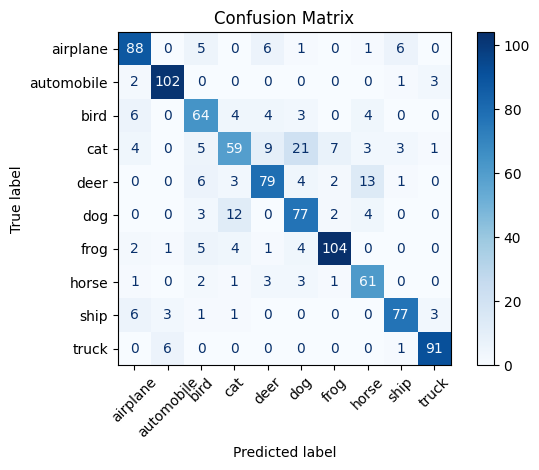

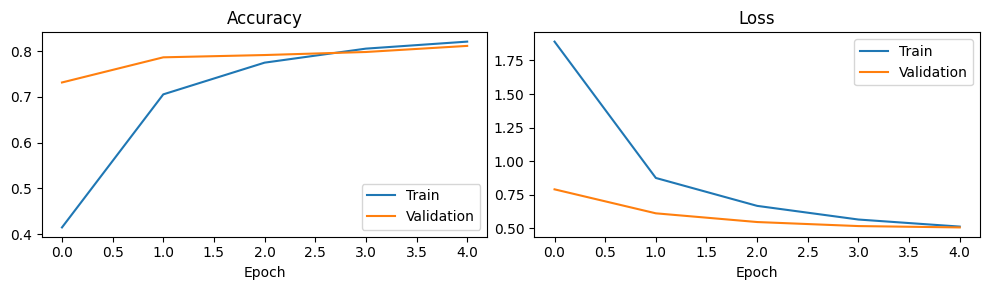

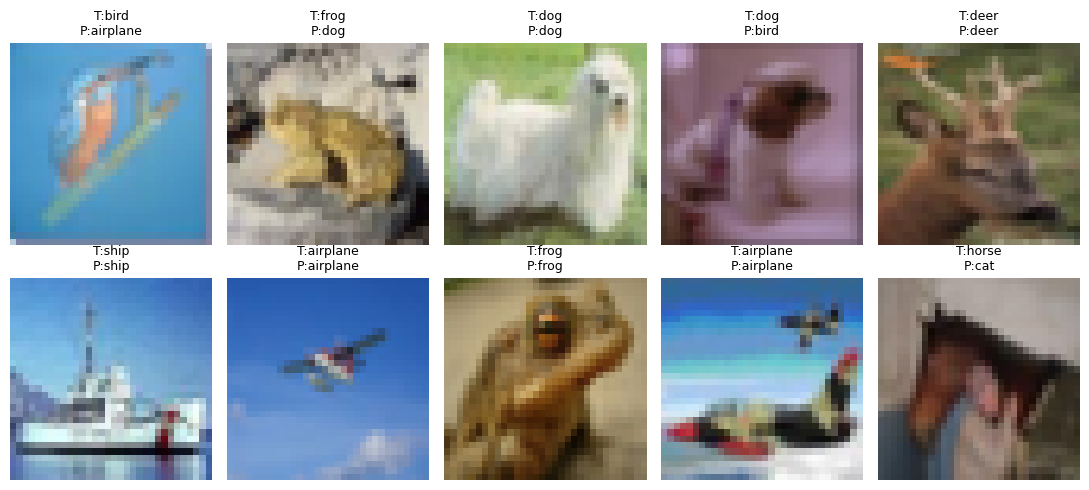

In [3]:
# Evaluation and visualizations
pred = model.predict(test,verbose=0).argmax(axis=1)
true = yt[ti]
print(classification_report(true,pred,labels=range(10),target_names=names,
                            digits=3,zero_division=0))
print('Accuracy:',round(np.mean(pred==true),4))
ConfusionMatrixDisplay(confusion_matrix(true,pred,labels=range(10)),
                       display_labels=names).plot(xticks_rotation=45,cmap='Blues')
plt.title('Confusion Matrix'); plt.tight_layout(); plt.show()

fig,ax=plt.subplots(1,2,figsize=(10,3))
for a,key in zip(ax,['accuracy','loss']):
    a.plot(h.history[key],label='Train')
    a.plot(h.history['val_'+key],label='Validation')
    a.set_title(key.title());a.set_xlabel('Epoch');a.legend()
plt.tight_layout();plt.show()

fig,ax=plt.subplots(2,5,figsize=(11,5))
for i,a in enumerate(ax.flat):
    a.imshow(xt[ti[i]]);a.set_title(f'T:{names[true[i]]}\nP:{names[pred[i]]}',fontsize=9)
    a.axis('off')
plt.tight_layout();plt.show()

## Result Analysis
The classification report prints **accuracy, precision, recall and F1-score**. The confusion matrix shows class-level errors. Compare the training and validation curves to assess potential overfitting. Dropout, augmentation and the frozen pretrained backbone help reduce overfitting. Results may be lower than full-dataset training because this fast demonstration uses only a small subset and two epochs.

**Observation:** After running, record the actual accuracy and the classes most frequently confused. Do not claim a benchmark score from this subset.

**References:** Krizhevsky (2009), *Learning Multiple Layers of Features from Tiny Images*; Sandler et al. (2018), *MobileNetV2: Inverted Residuals and Linear Bottlenecks*.